pip install gdown

pip install PyDrive

pip install --upgrade matplotlib

# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
warnings.filterwarnings('ignore')

# a_eendpt

In [333]:
df1=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\a_eendpt.csv")

In [334]:
df1.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,PANIT,CETUXDY,CETUX,WOEGFRDY,WOEGFR,POTOSDY,POTOS,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,0.0,249.0,0.0,249.0,0.0,249.0,0.0,219.0,0,Fully active
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,0.0,94.0,0.0,94.0,0.0,116.0,1.0,60.0,0,Fully active
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,0.0,729.0,0.0,686.0,1.0,517.0,1.0,437.0,0,Fully active
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,0.0,308.0,0.0,308.0,0.0,280.0,1.0,220.0,0,Fully active
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,0.0,15.0,0.0,15.0,0.0,15.0,0.0,3.0,1,Symptoms but ambulatory


In [335]:
df1.shape

(946, 140)

In [336]:
df1.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD',
       ...
       'PANIT', 'CETUXDY', 'CETUX', 'WOEGFRDY', 'WOEGFR', 'POTOSDY', 'POTOS',
       'TRTDUR', 'B_ECOGCD', 'B_ECOG'],
      dtype='object', length=140)

In [337]:
desired_columns = ['SUBJID','AGE','SEXCD','TRTDOSE','ATRT','PRBEVRCDR','PRBEVCD','PROXACDR','PROXAM','PFSCR','PFSCRV','PDLR','TRTDUR','B_METANM','KRAS','DIAGTYPCD','TUMCAT','LIVRONLY','PFSCR','PDLR']  
existing_columns = [col for col in desired_columns if col in df1.columns]
df1 = df1[existing_columns]

In [338]:
df1.shape

(946, 18)

In [339]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 946 entries, 0 to 945
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SUBJID    946 non-null    int64  
 1   AGE       946 non-null    float64
 2   SEXCD     946 non-null    object 
 3   TRTDOSE   471 non-null    float64
 4   ATRT      946 non-null    object 
 5   PRBEVCD   946 non-null    float64
 6   PROXACDR  946 non-null    float64
 7   PROXAM    946 non-null    object 
 8   PFSCR     946 non-null    float64
 9   PFSCRV    946 non-null    float64
 10  PDLR      946 non-null    float64
 11  TRTDUR    946 non-null    float64
 12  B_METANM  941 non-null    float64
 13  KRAS      885 non-null    object 
 14  TUMCAT    946 non-null    object 
 15  LIVRONLY  946 non-null    object 
 16  PFSCR     946 non-null    float64
 17  PDLR      946 non-null    float64
dtypes: float64(11), int64(1), object(6)
memory usage: 133.2+ KB


In [340]:
df1.describe()

,SUBJID,AGE,TRTDOSE,PRBEVCD,PROXACDR,PFSCR,PFSCRV,PDLR,TRTDUR,B_METANM,PFSCR,PDLR
count,9.460000e+02,946.000000,471.0,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000,941.000000,946.000000,946.000000
mean,2.024380e+08,60.557082,6.0,0.157505,0.650106,0.939746,0.968288,0.794926,162.082452,2.565356,0.939746,0.794926
std,1.117732e+06,10.570970,0.0,0.364469,0.477189,0.238082,0.175326,0.403969,142.268565,1.180169,0.238082,0.403969
min,2.010010e+08,28.000000,6.0,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,0.000000
25%,2.013220e+08,54.000000,6.0,0.000000,0.000000,1.000000,1.000000,1.000000,52.000000,2.000000,1.000000,1.000000
50%,2.021045e+08,61.000000,6.0,0.000000,1.000000,1.000000,1.000000,1.000000,132.500000,2.000000,1.000000,1.000000
75%,2.036070e+08,69.000000,6.0,0.000000,1.000000,1.000000,1.000000,1.000000,220.750000,3.000000,1.000000,1.000000
max,2.039080e+08,86.000000,6.0,1.000000,1.000000,1.000000,1.000000,1.000000,1262.000000,8.000000,1.000000,1.000000


In [341]:
df1.nunique()

SUBJID      946
AGE          55
SEXCD         2
TRTDOSE       1
ATRT          2
PRBEVCD       2
PROXACDR      2
PROXAM        2
PFSCR         2
PFSCRV        2
PDLR          2
TRTDUR      297
B_METANM      7
KRAS          3
TUMCAT        2
LIVRONLY      2
PFSCR         2
PDLR          2
dtype: int64

In [342]:
df1.isnull().sum()

SUBJID        0
AGE           0
SEXCD         0
TRTDOSE     475
ATRT          0
PRBEVCD       0
PROXACDR      0
PROXAM        0
PFSCR         0
PFSCRV        0
PDLR          0
TRTDUR        0
B_METANM      5
KRAS         61
TUMCAT        0
LIVRONLY      0
PFSCR         0
PDLR          0
dtype: int64

# a_endpt

In [343]:
df2=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\a_endpt.csv")

In [344]:
df2.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,ANTUMDY,ANTUM,WOEGFRDY,WOEGFR,POTOSDY,POTOS,TRTDUR,B_ECOGCD,B_ECOG,NPRSURG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,271.0,1.0,249.0,0.0,249.0,0.0,219.0,0,Fully active,1
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,116.0,1.0,94.0,0.0,116.0,1.0,60.0,0,Fully active,1
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,517.0,1.0,686.0,1.0,517.0,1.0,437.0,0,Fully active,3
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,280.0,1.0,308.0,0.0,280.0,1.0,220.0,0,Fully active,2
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,15.0,0.0,15.0,0.0,15.0,0.0,3.0,1,Symptoms but ambulatory,1


In [345]:
df2.shape

(946, 195)

In [346]:
df2.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD',
       ...
       'ANTUMDY', 'ANTUM', 'WOEGFRDY', 'WOEGFR', 'POTOSDY', 'POTOS', 'TRTDUR',
       'B_ECOGCD', 'B_ECOG', 'NPRSURG'],
      dtype='object', length=195)

In [347]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 946 entries, 0 to 945
Columns: 195 entries, STUDYID to NPRSURG
dtypes: float64(132), int64(3), object(60)
memory usage: 1.4+ MB


In [348]:
desired_columns = ['SUBJID','B_ALPNM', 'B_CEA', 'B_CREAT', 'CDOSE',  'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE', 'DIAGMONS', 'METMONS','BIOPTPCT', 'BIOPRS']
existing_columns = [col for col in desired_columns if col in df2.columns]
df2 = df2[existing_columns]

In [349]:
df2.shape

(946, 14)

In [350]:
df2.head()

,SUBJID,B_ALPNM,B_CEA,B_CREAT,CDOSE,IRCDOSE,FBDUR,FBCDOSE,FIDUR,FICDOSE,DIAGMONS,METMONS,BIOPTPCT,BIOPRS
0,201001001,106.0,17.5,97.240,7680.0,5804.98,230.0,12900.05,230.0,77418.00,9.540984,9.540984,61.28,Positive
1,201001002,173.0,18.1,87.516,2790.0,1900.20,71.0,4222.70,71.0,25341.69,6.131148,6.131148,43.22,Positive
2,201001004,175.0,252.6,78.676,10044.0,8115.57,448.0,15045.67,448.0,93367.44,12.327869,12.852459,46.74,Negative
3,201001005,170.0,609.9,89.284,8904.0,6171.37,231.0,13714.88,231.0,82300.00,9.803279,9.803279,23.90,Positive
4,201001006,207.0,70.7,104.312,NaN,360.00,14.0,800.00,14.0,4800.00,2.885246,3.540984,42.19,Positive


# Merging Files

In [351]:
df=pd.merge(df1,df2,on='SUBJID',how='inner')

In [352]:
df.shape

(946, 31)

# a_sendpt

In [353]:
df3=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\a_sendpt.csv")

In [354]:
df3.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,NASEVCD,NASEV,NASEVDY,NADUR,NADURC,NASEVDUR,NASEVDRC,B_ECOGCD,B_ECOG,TRTDUR
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,0.0,NaN,246.0,NaN,NaN,NaN,NaN,0,Fully active,219.0
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,0.0,NaN,88.0,NaN,NaN,NaN,NaN,0,Fully active,60.0
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,0.0,NaN,463.0,NaN,NaN,NaN,NaN,0,Fully active,437.0
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,0.0,NaN,245.0,NaN,NaN,NaN,NaN,0,Fully active,220.0
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,0.0,NaN,0.0,NaN,NaN,NaN,NaN,1,Symptoms but ambulatory,3.0


In [355]:
df3.shape

(946, 236)

In [356]:
df3.isnull().sum()

STUDYID       0
SITEID        0
SUBJID        0
AGE           0
SEXCD         0
           ... 
NASEVDUR    821
NASEVDRC    821
B_ECOGCD      0
B_ECOG        0
TRTDUR        0
Length: 236, dtype: int64

In [357]:
common_columns = set(df.columns).intersection(set(df3.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'FICDOSE', 'SEXCD', 'FBCDOSE', 'PRBEVCD', 'IRCDOSE', 'SUBJID', 'TRTDOSE', 'CDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [358]:
desired_columns = ['SUBJID','CDOSE','DSDLYPC','CHDLYNM','CHDLYPC','PROPDOSE']  
existing_columns = [col for col in desired_columns if col in df3.columns]
df3 = df3[existing_columns]

In [359]:
df3.shape

(946, 6)

In [360]:
df3.head()

,SUBJID,CDOSE,DSDLYPC,CHDLYNM,CHDLYPC,PROPDOSE
0,201001001,7680.0,0.062500,1.0,0.062500,3.041537
1,201001002,2790.0,NaN,NaN,NaN,2.770317
2,201001004,10044.0,0.259259,7.0,0.259259,2.845723
3,201001005,8904.0,0.133333,2.0,0.133333,2.732272
4,201001006,NaN,NaN,NaN,NaN,NaN


In [361]:
df3.isnull().sum()

SUBJID        0
CDOSE       476
DSDLYPC     311
CHDLYNM     317
CHDLYPC     317
PROPDOSE    470
dtype: int64

In [362]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 946 entries, 0 to 945
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SUBJID    946 non-null    int64  
 1   CDOSE     470 non-null    float64
 2   DSDLYPC   635 non-null    float64
 3   CHDLYNM   629 non-null    float64
 4   CHDLYPC   629 non-null    float64
 5   PROPDOSE  476 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 44.5 KB


In [363]:
df3.describe()

,SUBJID,CDOSE,DSDLYPC,CHDLYNM,CHDLYPC,PROPDOSE
count,9.460000e+02,470.000000,635.000000,629.000000,629.000000,476.000000
mean,2.024380e+08,4732.632298,0.265329,2.901431,0.267695,2.788967
std,1.117732e+06,4101.909839,0.174904,2.782992,0.175119,0.511555
min,2.010010e+08,235.000000,0.027778,1.000000,0.027778,0.000000
25%,2.013220e+08,1761.000000,0.125000,1.000000,0.125000,2.550416
50%,2.021045e+08,3529.500000,0.240000,2.000000,0.250000,2.817968
75%,2.036070e+08,6387.500000,0.333333,4.000000,0.333333,3.105602
max,2.039080e+08,29340.000000,0.846154,29.000000,0.846154,4.774268


In [364]:
df=pd.merge(df,df3,on='SUBJID',how='inner')

In [365]:
df.shape

(946, 36)

# chemotx

In [366]:
df4=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\chemotx.csv")

In [367]:
df4.shape

(2283, 70)

In [368]:
df4.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,CHPREF,CHSTDTV,CHDRSNCD,CHDREAS,CHRESPCD,CHRESP,TRTDUR,CHPDDY,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,FLUOROURACIL,14FEB2006,7.0,Disease progression,4.0,Stable disease,219.0,-54.0,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,OXALIPLATIN,14FEB2006,7.0,Disease progression,4.0,Stable disease,219.0,-54.0,0,Fully active
2,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,CAPECITABINE,29MAY2006,7.0,Disease progression,5.0,Progressive disease,60.0,-80.0,0,Fully active
3,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,OXALIPLATIN,29MAY2006,7.0,Disease progression,5.0,Progressive disease,60.0,-80.0,0,Fully active
4,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,CAPECITABINE,07FEB2006,7.0,Disease progression,3.0,Partial response,437.0,-39.0,0,Fully active


In [369]:
common_columns = set(df.columns).intersection(set(df4.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [370]:
desired_columns = ['SUBJID','CHANY','CHTERM','CHDRSNCD','CHRESPCD']  
existing_columns = [col for col in desired_columns if col in df4.columns]
df4 = df4[existing_columns]

In [371]:
df4.head()

,SUBJID,CHANY,CHTERM,CHDRSNCD,CHRESPCD
0,201001001,Y,5-FU,7.0,4.0
1,201001001,Y,OXALIPLATIN,7.0,4.0
2,201001002,Y,CAPECITABINE,7.0,5.0
3,201001002,Y,OXALIPLATIN,7.0,5.0
4,201001004,Y,CAPECITABINE,7.0,3.0


In [372]:
df4.shape

(2283, 5)

In [373]:
df4.isnull().sum()

SUBJID        0
CHANY         0
CHTERM        0
CHDRSNCD    333
CHRESPCD    327
dtype: int64

In [374]:
numerical_cols = [ 'CHRESPCD', 'CHDRSNCD']
categorical_cols = ['CHTERM', 'CHANY']
numerical_aggregated = df4.groupby('SUBJID')[numerical_cols].mean().reset_index()

categorical_encoded = pd.get_dummies(df4[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df4[['SUBJID']].join(categorical_encoded)
categorical_aggregated = categorical_aggregated.groupby('SUBJID').max().reset_index()

df4 = pd.merge(numerical_aggregated, categorical_aggregated, on='SUBJID', how='left')


In [375]:
threshold = 0.90
zero_proportion = (df4 == 0).mean()
columns_to_keep = zero_proportion[zero_proportion < threshold].index
df4 = df4[columns_to_keep]

In [376]:
df4.shape

(941, 9)

In [377]:
df4.head()

,SUBJID,CHRESPCD,CHDRSNCD,CHTERM_5 FU,CHTERM_5-FU,CHTERM_CAPECITABINE,CHTERM_LEUCOVORIN,CHTERM_OXALIPLATIN,CHANY_Y
0,201001001,4.0,7.0,0,1,0,0,1,1
1,201001002,5.0,7.0,0,0,1,0,1,1
2,201001004,3.0,7.0,0,0,1,0,1,1
3,201001005,3.0,7.0,0,0,1,0,1,1
4,201001006,5.0,7.0,0,0,1,0,1,1


In [378]:
df4.nunique()

SUBJID                 941
CHRESPCD                 8
CHDRSNCD                 5
CHTERM_5 FU              2
CHTERM_5-FU              2
CHTERM_CAPECITABINE      2
CHTERM_LEUCOVORIN        2
CHTERM_OXALIPLATIN       2
CHANY_Y                  1
dtype: int64

# Merge Files

In [379]:
df=pd.merge(df,df4,on='SUBJID',how='left')

In [380]:
df.shape

(946, 44)

# death

In [381]:
df5=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\death.csv")

In [382]:
df5.shape

(837, 62)

In [383]:
df5.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,B_ECOG,TRTDUR,DTHDY,DTHDYI,DTHDYI2,PHASECD,PHASE,DTCAUSCD,DTCAUS,DTAEPT
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Fully active,219.0,294.0,294.0,294.0,60.0,Long-term follow-up,7.0,Disease progression,NaN
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Fully active,60.0,134.0,134.0,134.0,60.0,Long-term follow-up,7.0,Disease progression,NaN
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,Fully active,437.0,789.0,789.0,789.0,60.0,Long-term follow-up,7.0,Disease progression,NaN
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Fully active,220.0,323.0,323.0,323.0,60.0,Long-term follow-up,7.0,Disease progression,NaN
4,20050181,1001,201001007,50.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,Fully active,52.0,233.0,233.0,233.0,60.0,Long-term follow-up,7.0,Disease progression,NaN


In [384]:
common_columns = set(df.columns).intersection(set(df5.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [385]:
desired_columns = ['SUBJID','DTCAUSCD']  
existing_columns = [col for col in desired_columns if col in df5.columns]
df5 = df5[existing_columns]

In [386]:
df5.shape

(837, 2)

In [387]:
df5.head()

,SUBJID,DTCAUSCD
0,201001001,7.0
1,201001002,7.0
2,201001004,7.0
3,201001005,7.0
4,201001007,7.0


In [388]:
df5.isnull().sum()

SUBJID      0
DTCAUSCD    4
dtype: int64

# Merge Files

In [389]:
df=pd.merge(df,df5,on='SUBJID',how='left')
df.shape

(946, 45)

# Demo

In [390]:
df6=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\demo.csv")

In [391]:
df6.shape

(946, 112)

In [392]:
df6.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,PREGTYPE,PREGRSCD,PREGRES,BIONANY,BIORSNCD,diagdy,metdxdy,biopdy,biopdy2,PREGDY
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,66.0,Not applicable,NaN,NaN,-293.0,-293.0,644.0,667.0,NaN
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,66.0,Not applicable,NaN,NaN,-193.0,-193.0,670.0,698.0,NaN
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,NaN,66.0,Not applicable,NaN,NaN,-381.0,-397.0,554.0,571.0,NaN
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,66.0,Not applicable,NaN,NaN,-306.0,-306.0,589.0,616.0,NaN
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,NaN,66.0,Not applicable,NaN,NaN,-89.0,-109.0,518.0,535.0,NaN


In [393]:
common_columns = set(df6.columns).intersection(set(df.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'PROXACDR', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'BIOPTPCT', 'PRBEVCD', 'SUBJID', 'TRTDOSE', 'METMONS', 'BIOPRS', 'B_METANM', 'DIAGMONS', 'LIVRONLY'}


In [394]:
desired_columns = ['SUBJID','DIAGMONS','BIOPACPT','BIOPCYTO']  
existing_columns = [col for col in desired_columns if col in df6.columns]
df6 = df6[existing_columns]

In [395]:
df6.head()

,SUBJID,DIAGMONS,BIOPACPT,BIOPCYTO
0,201001001,9.540984,Y,2.1
1,201001002,6.131148,Y,0.0
2,201001004,12.327869,Y,0.0
3,201001005,9.803279,Y,0.0
4,201001006,2.885246,Y,5.1


In [396]:
df6.isnull().sum()

SUBJID        0
DIAGMONS     37
BIOPACPT     11
BIOPCYTO    286
dtype: int64

# Merge Files

In [397]:
df=pd.merge(df,df6,on='SUBJID',how='left')

In [398]:
df.shape

(946, 48)

# Disposit

In [399]:
df7=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\disposit.csv")

In [400]:
df7.shape

(946, 89)

In [401]:
df7.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,LCTTXDY,DSDY,DECISDY,EOIPDY,EOPPDY,EORADDY,LASTOSDY,LASTCTDY,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,219.0,247.0,240.0,240.0,240.0,NaN,248.0,248.0,0,Fully active
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,60.0,89.0,71.0,71.0,71.0,NaN,89.0,89.0,0,Fully active
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,437.0,464.0,456.0,456.0,456.0,NaN,464.0,725.0,0,Fully active
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,220.0,246.0,232.0,232.0,232.0,NaN,246.0,302.0,0,Fully active
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,3.0,1.0,15.0,NaN,15.0,NaN,15.0,15.0,1,Symptoms but ambulatory


In [402]:
common_columns = set(df7.columns).intersection(set(df.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [403]:
desired_columns = ['SUBJID','PFUP']        
existing_columns = [col for col in desired_columns if col in df7.columns]
df7 = df7[existing_columns]

In [404]:
df7.head()

,SUBJID,PFUP
0,201001001,202.0
1,201001002,200.0
2,201001004,188.0
3,201001005,186.0
4,201001006,183.0


In [405]:
df7.shape

(946, 2)

In [406]:
df7.isnull().sum()

SUBJID    0
PFUP      0
dtype: int64

# Merge Files

In [407]:
df=pd.merge(df,df7,on='SUBJID',how='left')

In [408]:
df.shape

(946, 49)

# Eligcrit

In [409]:
df8=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\eligcrit.csv")

In [410]:
df8.shape

(1062, 56)

In [411]:
df8.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,KRAS,EVALITT,EVALPP,EVALQOL,EVALEGFR,B_ECOGCD,B_ECOG,TRTDUR,ELIGIBLE,ELIGNMCD
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Mutant,Y,Y,Y,Y,0,Fully active,219.0,Y,NaN
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Mutant,Y,Y,Y,Y,0,Fully active,60.0,Y,NaN
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,Wild-type,Y,Y,Y,Y,0,Fully active,437.0,Y,NaN
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Wild-type,Y,Y,Y,Y,0,Fully active,220.0,Y,NaN
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,Failed,Y,Y,N,Y,1,Symptoms but ambulatory,3.0,Y,NaN


In [412]:
df8.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD',
       'ATRT', 'PRBEVCDR', 'PRBEVR', 'PRBEVCDM', 'PRBEVM', 'PRBEVCD', 'PRBEV',
       'PROXACDR', 'PROXAR', 'PROXACDM', 'PROXAM', 'PROXALCD', 'PROXAL',
       'B_METANM', 'B_METACT', 'LIVRONCD', 'LIVRONLY', 'PADJYNCD', 'PRADJYN',
       'DPADJUV', 'B_LDHYN', 'B_LDH2YN', 'B_LDHNM', 'BECOGICD', 'B_ECOGI',
       'BECGICT', 'DIAGTYCD', 'DIAGTYPE', 'TUMCATCD', 'TUMCAT', 'LIVERMET',
       'KRASCD', 'KRAS', 'EVALITT', 'EVALPP', 'EVALQOL', 'EVALEGFR',
       'B_ECOGCD', 'B_ECOG', 'TRTDUR', 'ELIGIBLE', 'ELIGNMCD'],
      dtype='object')

In [413]:
common_columns = set(df8.columns).intersection(set(df.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [414]:
desired_columns = ['SUBJID','KRASCD', 'EVALITT']  
existing_columns = [col for col in desired_columns if col in df8.columns]
df8 = df8[existing_columns]

In [415]:
df8.shape

(1062, 3)

In [416]:
df8.head()

,SUBJID,KRASCD,EVALITT
0,201001001,2.0,Y
1,201001002,2.0,Y
2,201001004,1.0,Y
3,201001005,1.0,Y
4,201001006,88.0,Y


In [417]:
numerical_cols = ['KRASCD']
categorical_cols = ['EVALITT']
numerical_aggregated = df8.groupby('SUBJID')[numerical_cols].mean().reset_index()

categorical_encoded = pd.get_dummies(df8[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df8[['SUBJID']].join(categorical_encoded)
categorical_aggregated = categorical_aggregated.groupby('SUBJID').max().reset_index()
df8 = pd.merge(numerical_aggregated, categorical_aggregated, on='SUBJID', how='left')

In [418]:
df8.shape

(946, 3)

# Merge Files

In [419]:
df=pd.merge(df,df8,on='SUBJID',how='left')

In [420]:
df.shape

(946, 51)

# exposure

In [421]:
df9=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\exposure.csv")

In [422]:
df9.shape

(46115, 94)

In [423]:
df9.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,EXREASCD,EXREAS,EXPPRSCD,EXCYCLNM,EXLOTID,EXINFRCT,EXENDY,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,1.0,L005289,N,NaN,219.0,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,1.0,NaN,NaN,1.0,219.0,0,Fully active
2,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,1.0,NaN,NaN,1.0,219.0,0,Fully active
3,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,1.0,NaN,NaN,1.0,219.0,0,Fully active
4,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,1.0,NaN,NaN,3.0,219.0,0,Fully active


In [424]:
common_columns = set(df9.columns).intersection(set(df.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'KRASCD', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [425]:
df9.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD',
       'ATRT', 'PRBEVCDR', 'PRBEVR', 'PRBEVCDM', 'PRBEVM', 'PRBEVCD', 'PRBEV',
       'PROXACDR', 'PROXAR', 'PROXACDM', 'PROXAM', 'PROXALCD', 'PROXAL',
       'B_METANM', 'B_METACT', 'LIVRONCD', 'LIVRONLY', 'PADJYNCD', 'PRADJYN',
       'DPADJUV', 'B_LDHYN', 'B_LDH2YN', 'B_LDHNM', 'BECOGICD', 'B_ECOGI',
       'BECGICT', 'DIAGTYCD', 'DIAGTYPE', 'TUMCATCD', 'TUMCAT', 'LIVERMET',
       'KRASCD', 'KRAS', 'EVALITT', 'EVALPP', 'EVALQOL', 'EVALEGFR',
       'DOSREFDY', 'DOSREFWK', 'ENRREFDY', 'ENRREFWK', 'VISITCD', 'VISIT',
       'PHASECD', 'PHASE', 'EXDURMN', 'ACTTRTCD', 'ACTTRT', 'DRUGTP', 'QTY',
       'QTYUNCD', 'QTYUNIT', 'CONC', 'CONCUNCD', 'CONCUNIT', 'DOSE',
       'DOSEUNCD', 'DOSEUNIT', 'WDOSE', 'WDOSUNCD', 'WDOSUNIT', 'BSADOSE',
       'ROUTECD', 'ROUTE', 'DOSEFRCD', 'DOSEFREQ', 'DOSINTYN', 'DOSDLAY',
       'EXDELDY', 'EXCHEMO', '

In [426]:
desired_columns = ['SUBJID','EXDURMN','ACTTRTCD','DOSE']  
existing_columns = [col for col in desired_columns if col in df9.columns]
df9 = df9[existing_columns]

In [427]:
df9.shape

(46115, 4)

In [428]:
df9.head()

,SUBJID,EXDURMN,ACTTRTCD,DOSE
0,201001001,65.0,1.0,480.0
1,201001001,90.0,72.0,361.8
2,201001001,120.0,73.0,804.0
3,201001001,4.0,75.0,804.0
4,201001001,2670.0,100.0,4824.0


In [429]:
numerical_cols = ['EXDURMN','ACTTRTCD','DOSE']
df9 = df9.groupby('SUBJID')[numerical_cols].mean().reset_index()

In [430]:
df9.shape

(946, 4)

In [431]:
df9.head()

,SUBJID,EXDURMN,ACTTRTCD,DOSE
0,201001001,601.700000,64.2,1458.689875
1,201001002,601.680000,64.2,1539.070000
2,201001004,604.614815,64.2,1069.501333
3,201001005,608.391892,64.2,1664.042267
4,201001006,754.250000,80.0,1690.000000


# Merge Files

In [432]:
df=pd.merge(df,df9,on='SUBJID',how='left')

In [433]:
df.shape

(946, 54)

# Lab

In [434]:
df10=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\lab.csv")

In [435]:
df10.shape

(406508, 95)

In [436]:
df10.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,LBANCMTH,LBGRDINC,LBGRDDEC,LBMIN,LBMAX,LBLAST,LBANALWK,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,0.0,N,N,N,NaN,219.0,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,0.0,N,N,N,1.0,219.0,0,Fully active
2,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,0.0,N,N,N,NaN,219.0,0,Fully active
3,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,0.0,N,N,N,NaN,219.0,0,Fully active
4,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,0.0,N,N,N,NaN,219.0,0,Fully active


In [437]:
common_columns = set(df10.columns).intersection(set(df.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'KRASCD', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [438]:
df10.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD',
       'ATRT', 'PRBEVCDR', 'PRBEVR', 'PRBEVCDM', 'PRBEVM', 'PRBEVCD', 'PRBEV',
       'PROXACDR', 'PROXAR', 'PROXACDM', 'PROXAM', 'PROXALCD', 'PROXAL',
       'B_METANM', 'B_METACT', 'LIVRONCD', 'LIVRONLY', 'PADJYNCD', 'PRADJYN',
       'DPADJUV', 'B_LDHYN', 'B_LDH2YN', 'B_LDHNM', 'BECOGICD', 'B_ECOGI',
       'BECGICT', 'DIAGTYCD', 'DIAGTYPE', 'TUMCATCD', 'TUMCAT', 'LIVERMET',
       'KRASCD', 'KRAS', 'EVALITT', 'EVALPP', 'EVALQOL', 'EVALEGFR',
       'DOSREFDY', 'DOSREFWK', 'ENRREFDY', 'ENRREFWK', 'VISITCD', 'VISIT',
       'PHASECD', 'PHASE', 'LBNUMINF', 'LBNUMCTX', 'LBANLCYC', 'LBREPEAT',
       'LBTYPECD', 'LBTYPE', 'LBPANEL', 'LBTESTCD', 'LBTEST', 'LBSTRESN',
       'LBSTRESC', 'LBSTUNIT', 'LBSTNRLO', 'LBSTNRHI', 'LBNRINCD', 'LBNRIND',
       'LBORRES', 'LBORRESN', 'LBORUNIT', 'LBORNRLO', 'LBORNRHI', 'LBBASE',
       'LBBLRES', 'LBC

In [439]:
df10.isnull().sum()

STUDYID          0
SITEID           0
SUBJID           0
AGE              0
SEXCD            0
             ...  
LBLAST           0
LBANALWK    267544
TRTDUR           0
B_ECOGCD         0
B_ECOG           0
Length: 95, dtype: int64

In [440]:
desired_columns = ['SUBJID','LBSTRESN','LBSTNRLO','LBSTNRHI','LBORRESN','LBBASE','LBBLRES','LBPHGCL']  
existing_columns = [col for col in desired_columns if col in df10.columns]
df10 = df10[existing_columns]

In [441]:
df10.shape

(406508, 7)

In [442]:
df10.head()

,SUBJID,LBSTRESN,LBSTNRLO,LBSTNRHI,LBORRESN,LBBASE,LBBLRES
0,201001001,44.3,32.0,45.0,44.3,N,41.9
1,201001001,41.9,32.0,45.0,41.9,Y,41.9
2,201001001,41.7,32.0,45.0,41.7,N,41.9
3,201001001,41.7,32.0,45.0,41.7,N,41.9
4,201001001,43.0,32.0,45.0,43.0,N,41.9


df10.isnull().sum()

In [443]:
categorical_cols = ['LBBASE']
numerical_cols = ['LBSTRESN','LBSTNRLO','LBSTNRHI','LBORRESN','LBBLRES'	]
numerical_aggregated = df10.groupby('SUBJID')[numerical_cols].mean().reset_index()

categorical_encoded = pd.get_dummies(df10[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df10[['SUBJID']].join(categorical_encoded)
categorical_aggregated = categorical_aggregated.groupby('SUBJID').max().reset_index()
df10 = pd.merge(numerical_aggregated, categorical_aggregated, on='SUBJID', how='left')

In [444]:
df10.shape

(946, 8)

In [445]:
df10.head()

,SUBJID,LBSTRESN,LBSTNRLO,LBSTNRHI,LBORRESN,LBBLRES,LBBASE_N,LBBASE_Y
0,201001001,53.119213,35.280165,75.074683,41.818998,56.476435,1,1
1,201001002,64.343600,35.105329,74.729192,53.325578,64.164232,1,1
2,201001004,49.464788,32.059051,71.639250,44.965637,61.685535,1,1
3,201001005,79.468639,35.192800,74.902961,68.844075,69.587457,1,1
4,201001006,77.984847,35.023115,74.565869,65.556491,81.226436,1,1


# Merge Files

In [446]:
df=pd.merge(df,df10,on='SUBJID',how='left')

In [447]:
df.shape

(946, 61)

# Lesion

In [448]:
df11=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\lesion.csv")

In [449]:
df11.shape

(71644, 87)

In [450]:
df11.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,LSSLDPCH,LSSLDPCN,LSRESPCD,LSRESP,LSPROGNY,LSEXAMNO,LSRI,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,219.0,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,3.0,4.0,219.0,0,Fully active
2,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,1.0,4.0,219.0,0,Fully active
3,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,1.0,4.0,219.0,0,Fully active
4,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,219.0,0,Fully active


In [451]:
df11.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD',
       'ATRT', 'PRBEVCDR', 'PRBEVR', 'PRBEVCDM', 'PRBEVM', 'PRBEVCD', 'PRBEV',
       'PROXACDR', 'PROXAR', 'PROXACDM', 'PROXAM', 'PROXALCD', 'PROXAL',
       'B_METANM', 'B_METACT', 'LIVRONCD', 'LIVRONLY', 'PADJYNCD', 'PRADJYN',
       'DPADJUV', 'B_LDHYN', 'B_LDH2YN', 'B_LDHNM', 'BECOGICD', 'B_ECOGI',
       'BECGICT', 'DIAGTYCD', 'DIAGTYPE', 'TUMCATCD', 'TUMCAT', 'LIVERMET',
       'KRASCD', 'KRAS', 'EVALITT', 'EVALPP', 'EVALQOL', 'EVALEGFR',
       'DOSREFDY', 'DOSREFWK', 'ENRREFDY', 'ENRREFWK', 'VISITCD', 'VISIT',
       'PHASECD', 'PHASE', 'LSTYPECD', 'LSTYPE', 'LSCATCD', 'LSCAT', 'LSANY',
       'LSNO', 'LSPERFNY', 'LSPIRRNY', 'LSSITECD', 'LSSITE', 'LSPROCCD',
       'LSPROC', 'LSRAWCD', 'LSRAW', 'LSNEW', 'LSNEWANY', 'LSLD', 'LSSLD',
       'LSSLDPCH', 'LSSLDPCN', 'LSRESPCD', 'LSRESP', 'LSPROGNY', 'LSEXAMNO',
       'LSRI', 'TRTDUR

In [452]:
df11['LSSLDPCN'].nunique()

253

In [453]:
desired_columns = ['SUBJID','DOSREFDY','LSTYPE','LSCAT','ENRREFDY','LSNEWANY','LSSLD','LSSLDPCH', 'LSSLDPCN','LSRI']  
existing_columns = [col for col in desired_columns if col in df11.columns]
df11 = df11[existing_columns]

desired_columns = ['SUBJID','DOSREFDY','LSTYPE','LSCAT','ENRREFDY','LSNEWANY','LSSLD','LSSLDPCH', 'LSSLDPCN','LSRI']  
existing_columns = [col for col in desired_columns if col in df11.columns]
df11 = df11[existing_columns]

In [454]:
df11.shape

(71644, 10)

In [455]:
df11.head()

,SUBJID,DOSREFDY,LSTYPE,LSCAT,ENRREFDY,LSNEWANY,LSSLD,LSSLDPCH,LSSLDPCN,LSRI
0,201001001,NaN,Local,Target lesion,NaN,NaN,NaN,NaN,NaN,NaN
1,201001001,-15.0,Central,NaN,-13.0,NaN,NaN,NaN,NaN,4.0
2,201001001,-15.0,Central,Target lesion,-13.0,N,49.0,NaN,NaN,4.0
3,201001001,-15.0,Central,Target lesion,-13.0,N,151.0,NaN,NaN,4.0
4,201001001,-15.0,Local,Target lesion,-13.0,NaN,118.0,NaN,NaN,NaN


def find_min_max_lssld_excl_zero(subjid_group):
    non_zero_lssld = subjid_group[subjid_group['LSSLD'] != 0]
    
    if not non_zero_lssld.empty:
        min_visitdy_y = non_zero_lssld['DOSREFDY'].min()
        max_visitdy_y = non_zero_lssld['DOSREFDY'].max()

        min_lssld = non_zero_lssld.loc[non_zero_lssld['DOSREFDY'] == min_visitdy_y, 'LSSLD'].min()
        max_lssld = non_zero_lssld.loc[non_zero_lssld['DOSREFDY'] == max_visitdy_y, 'LSSLD'].max()

        change_in_tumor_size = max_lssld - min_lssld

        return pd.Series({
            'min_DOSREFDY': min_visitdy_y,
            'min_LSSLD': min_lssld,
            'max_DOSREFDY': max_visitdy_y,
            'max_LSSLD': max_lssld,
            'LSSLD_Diff': change_in_tumor_size,
            # Calculate percentage change
            'Percentage_LSSLD_Change': (change_in_tumor_size / max_lssld) * 100 if min_lssld != 0 else None
        })
    else:
        return pd.Series({
            'min_DOSREFDY': None,
            'min_LSSLD': None,
            'max_DOSREFDY': None,
            'max_LSSLD': None,
            'LSSLD_Diff': None,
            'Percentage_LSSLD_Change': None
        })


# Apply the function to group by 'SUBJID' and calculate required metrics
results = df11.groupby('SUBJID').apply(find_min_max_lssld_excl_zero).reset_index()

# Print the resulting DataFrame
print(results)

results['LSSLD_Change'] = np.where(results['Percentage_LSSLD_Change'] > 30, 1, 0)

df11=df11.merge(results,on='SUBJID',how='inner')

In [456]:
df11.head()

,SUBJID,DOSREFDY,LSTYPE,LSCAT,ENRREFDY,LSNEWANY,LSSLD,LSSLDPCH,LSSLDPCN,LSRI
0,201001001,NaN,Local,Target lesion,NaN,NaN,NaN,NaN,NaN,NaN
1,201001001,-15.0,Central,NaN,-13.0,NaN,NaN,NaN,NaN,4.0
2,201001001,-15.0,Central,Target lesion,-13.0,N,49.0,NaN,NaN,4.0
3,201001001,-15.0,Central,Target lesion,-13.0,N,151.0,NaN,NaN,4.0
4,201001001,-15.0,Local,Target lesion,-13.0,NaN,118.0,NaN,NaN,NaN


In [457]:
categorical_cols = ['LSTYPE','LSCAT','LSNEWANY']
numerical_cols = ['DOSREFDY','ENRREFDY','LSSLD','LSSLDPCH','LSSLDPCN','LSRI']
numerical_aggregated = df11.groupby('SUBJID')[numerical_cols].mean().reset_index()

categorical_encoded = pd.get_dummies(df11[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df11[['SUBJID']].join(categorical_encoded)
categorical_aggregated = categorical_aggregated.groupby('SUBJID').max().reset_index()
df11 = pd.merge(numerical_aggregated, categorical_aggregated, on='SUBJID', how='left')

# Merge Files

dfx=pd.merge(df,dfx,on='SUBJID',how='left')
dfy=pd.merge(df,dfy,on='SUBJID',how='left')

dfx.shape

In [458]:
df=pd.merge(df,df11,on='SUBJID',how='left')

In [459]:
df.shape

(946, 74)

# Lesnprog

In [460]:
df12=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\lesnprog.csv")

In [461]:
df12.shape

(128, 60)

In [462]:
df12.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,EVALEGFR,DOSREFDY,DOSREFWK,LPWK,VISITCD,VISIT,LPSUM,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001011,62.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,Y,60.0,9.0,08,UNSCHED,Unscheduled visit,100.0,59.0,0,Fully active
1,20050181,1010,201010002,58.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,Y,59.0,9.0,8,UNSCHED,Unscheduled visit,78.0,90.0,0,Fully active
2,20050181,1103,201103005,49.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,Y,113.0,17.0,16,UNSCHED,Unscheduled visit,19.0,115.0,0,Fully active
3,20050181,1103,201103007,68.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Y,512.0,74.0,72,UNSCHED,Unscheduled visit,32.0,584.0,0,Fully active
4,20050181,1103,201103008,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Y,-21.0,-3.0,SCR,UNSCHED,Unscheduled visit,17.0,178.0,0,Fully active


In [463]:
common_columns = set(df12.columns).intersection(set(df.columns))
print("Common columns:", common_columns)

Common columns: {'TUMCAT', 'ATRT', 'KRAS', 'DOSREFDY', 'TRTDUR', 'PROXAM', 'AGE', 'SEXCD', 'PRBEVCD', 'SUBJID', 'KRASCD', 'TRTDOSE', 'PROXACDR', 'B_METANM', 'LIVRONLY'}


In [464]:
desired_columns = ['SUBJID','LPSUM']  
existing_columns = [col for col in desired_columns if col in df12.columns]
df12 = df12[existing_columns]

In [465]:
df12.head()

,SUBJID,LPSUM
0,201001011,100.0
1,201010002,78.0
2,201103005,19.0
3,201103007,32.0
4,201103008,17.0


In [466]:
numerical_cols = ['LPSUM']
df12 = df12.groupby('SUBJID')[numerical_cols].mean().reset_index()

In [467]:
df12['SUBJID'].nunique()

39

In [468]:
df12.shape

(39, 2)

In [469]:
df12.head()

,SUBJID,LPSUM
0,201001011,100.0
1,201010002,78.0
2,201103005,19.0
3,201103007,32.0
4,201103008,20.5


In [470]:
df12.isnull().sum()

SUBJID    0
LPSUM     1
dtype: int64

# Merge Files

dfx=pd.merge(dfx,df12,on='SUBJID',how='left')
dfy=pd.merge(dfy,df12,on='SUBJID',how='left')

In [471]:
df=pd.merge(df,df12,on='SUBJID',how='left')

In [472]:
df.shape

(946, 75)

# Medhis

In [473]:
df13=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\medhist.csv")

In [474]:
df13.shape

(4845, 66)

In [475]:
df13.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,MHCOND,MHSITECD,MHSITE,MHTERM,MHSTATCD,MHSTAT,TRTDUR,B_ECOGCD,B_ECOG,MHSTDY
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,219.0,0,Fully active,NaN
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,60.0,0,Fully active,NaN
2,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,ATRIAL FIBRILATION,1.0,Current or continuing,60.0,0,Fully active,NaN
3,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,PULMONARY EMBOLIA,1.0,Current or continuing,60.0,0,Fully active,NaN
4,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,437.0,0,Fully active,NaN


In [476]:
df13.isnull().sum()

STUDYID        0
SITEID         0
SUBJID         0
AGE            0
SEXCD          0
            ... 
MHSTAT      1098
TRTDUR         0
B_ECOGCD       0
B_ECOG         0
MHSTDY      4845
Length: 66, dtype: int64

In [477]:
df13.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD',
       'ATRT', 'PRBEVCDR', 'PRBEVR', 'PRBEVCDM', 'PRBEVM', 'PRBEVCD', 'PRBEV',
       'PROXACDR', 'PROXAR', 'PROXACDM', 'PROXAM', 'PROXALCD', 'PROXAL',
       'B_METANM', 'B_METACT', 'LIVRONCD', 'LIVRONLY', 'PADJYNCD', 'PRADJYN',
       'DPADJUV', 'B_LDHYN', 'B_LDH2YN', 'B_LDHNM', 'BECOGICD', 'B_ECOGI',
       'BECGICT', 'DIAGTYCD', 'DIAGTYPE', 'TUMCATCD', 'TUMCAT', 'LIVERMET',
       'KRASCD', 'KRAS', 'EVALITT', 'EVALPP', 'EVALQOL', 'EVALEGFR', 'MHANY',
       'MHBNGNYN', 'MHBSYSCD', 'MHBODSYS', 'MHCONDCD', 'MHCOND', 'MHSITECD',
       'MHSITE', 'MHTERM', 'MHSTATCD', 'MHSTAT', 'TRTDUR', 'B_ECOGCD',
       'B_ECOG', 'MHSTDY'],
      dtype='object')

In [478]:
desired_columns = ['SUBJID','MHANY','MHBNGNYN','MHSITE','MHTERM','MHSTAT']  
existing_columns = [col for col in desired_columns if col in df13.columns]
df13 = df13[existing_columns]

In [479]:
df13.head()

,SUBJID,MHANY,MHBNGNYN,MHSITE,MHTERM,MHSTAT
0,201001001,N,N,NaN,NaN,NaN
1,201001002,Y,N,NaN,NaN,NaN
2,201001002,Y,N,NaN,ATRIAL FIBRILATION,Current or continuing
3,201001002,Y,N,NaN,PULMONARY EMBOLIA,Current or continuing
4,201001004,N,N,NaN,NaN,NaN


In [480]:
categorical_cols = ['MHANY','MHBNGNYN','MHSITE','MHTERM','MHSTAT']
categorical_encoded = pd.get_dummies(df13[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df13[['SUBJID']].join(categorical_encoded)
df13 = categorical_aggregated.groupby('SUBJID').max().reset_index()

In [481]:
df13.shape

(946, 2440)

In [482]:
df13.head()

,SUBJID,MHANY_N,MHANY_Y,MHBNGNYN_N,MHBNGNYN_Y,MHSITE_Adrenal gland,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,...,MHTERM_VOCAL CORD SQUAMOUS CELL CARCINOMA,MHTERM_VOCAL CORDS CARCINOMA,MHTERM_VOMITING,MHTERM_VOMITING INTERMITTENT,MHTERM_WEEKNESS GRADE 2,MHTERM_WEIGHT LOSS,MHTERM_WRIST FRACTURE,MHTERM_ZONA,MHSTAT_Current or continuing,MHSTAT_Resolved
0,201001001,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,201001002,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,201001004,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,201001005,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,201001006,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1


In [483]:
threshold = 0.90
zero_proportion = (df13 == 0).mean()
columns_to_keep = zero_proportion[zero_proportion < threshold].index
df13 = df13[columns_to_keep]

In [484]:
df13.head()

,SUBJID,MHANY_N,MHANY_Y,MHBNGNYN_N,MHBNGNYN_Y,MHTERM_HYPERTENSION,MHSTAT_Current or continuing,MHSTAT_Resolved
0,201001001,1,0,1,0,0,0,0
1,201001002,0,1,1,0,0,1,0
2,201001004,1,0,1,0,0,0,0
3,201001005,0,1,1,0,0,0,1
4,201001006,0,1,1,0,0,1,1


In [485]:
df13.shape

(946, 8)

# Merge Files

In [486]:
df=pd.merge(df,df13,on='SUBJID',how='left')

In [487]:
df.shape

(946, 82)

# othcantx

In [488]:
df14=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\othcantx.csv")

In [489]:
df14.shape

(2302, 73)

In [490]:
df14.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,OTINTCD,OTINT,OTDRSNCD,OTDREAS,OTRESPCD,OTRESP,TRTDUR,OTPDDY,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,219.0,NaN,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,7.0,Disease progression,4.0,Stable disease,219.0,-53.0,0,Fully active
2,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,7.0,Disease progression,4.0,Stable disease,219.0,-53.0,0,Fully active
3,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,219.0,NaN,0,Fully active
4,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,60.0,NaN,0,Fully active


In [491]:
df14['OTINT'].unique()

array([nan, 'Palliative', 'Curative', 'Other'], dtype=object)

In [492]:
desired_columns = ['SUBJID','OTANY']  
existing_columns = [col for col in desired_columns if col in df14.columns]
df14 = df14[existing_columns]

In [493]:
df14.head()

,SUBJID,OTANY
0,201001001,Y
1,201001001,Y
2,201001001,Y
3,201001001,Y
4,201001002,N


In [494]:
df14.isnull().sum()

SUBJID    0
OTANY     0
dtype: int64

In [495]:
categorical_cols = ['OTANY']
categorical_encoded = pd.get_dummies(df14[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df14[['SUBJID']].join(categorical_encoded)
df14= categorical_aggregated.groupby('SUBJID').max().reset_index()

In [496]:
df14.head()

,SUBJID,OTANY_N,OTANY_Y
0,201001001,0,1
1,201001002,1,0
2,201001004,1,0
3,201001005,1,0
4,201001006,1,0


In [497]:
df14.shape

(946, 3)

# Merge Files

In [498]:
df=pd.merge(df,df14,on='SUBJID',how='left')

In [499]:
df.shape

(946, 84)

# Radio

In [500]:
df15=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\radiotx.csv")

In [501]:
df15.shape

(988, 67)

In [502]:
df15.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,RASTDYE,RAENDY,RASITECD,RASITE,RAINTCD,RAINT,RADPAREA,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,219.0,0,Fully active
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.0,0,Fully active
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,437.0,0,Fully active
3,20050181,1001,201001005,75.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,220.0,0,Fully active
4,20050181,1001,201001006,52.0,M,Male,1.0,White or Caucasian,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,1,Symptoms but ambulatory


In [503]:
df15.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD',
       'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD',
       'ATRT', 'PRBEVCDR', 'PRBEVR', 'PRBEVCDM', 'PRBEVM', 'PRBEVCD', 'PRBEV',
       'PROXACDR', 'PROXAR', 'PROXACDM', 'PROXAM', 'PROXALCD', 'PROXAL',
       'B_METANM', 'B_METACT', 'LIVRONCD', 'LIVRONLY', 'PADJYNCD', 'PRADJYN',
       'DPADJUV', 'B_LDHYN', 'B_LDH2YN', 'B_LDHNM', 'BECOGICD', 'B_ECOGI',
       'BECGICT', 'DIAGTYCD', 'DIAGTYPE', 'TUMCATCD', 'TUMCAT', 'LIVERMET',
       'KRASCD', 'KRAS', 'EVALITT', 'EVALPP', 'EVALQOL', 'EVALEGFR', 'RAANY',
       'VISITCD', 'VISIT', 'PHASECD', 'PHASE', 'RASTDY', 'RASTDYE', 'RAENDY',
       'RASITECD', 'RASITE', 'RAINTCD', 'RAINT', 'RADPAREA', 'TRTDUR',
       'B_ECOGCD', 'B_ECOG'],
      dtype='object')

In [504]:
desired_columns = ['SUBJID','RAANY']  
existing_columns = [col for col in desired_columns if col in df15.columns]
df15 = df15[existing_columns]

In [505]:
df15.head()

,SUBJID,RAANY
0,201001001,N
1,201001002,N
2,201001004,N
3,201001005,N
4,201001006,N


In [506]:
df15.isnull().sum()

SUBJID    0
RAANY     0
dtype: int64

In [507]:
df15.shape

(988, 2)

In [508]:
categorical_cols = ['RAANY']
categorical_encoded = pd.get_dummies(df15[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df15[['SUBJID']].join(categorical_encoded)
df15= categorical_aggregated.groupby('SUBJID').max().reset_index()

In [509]:
df15.shape

(946, 3)

In [510]:
df15.head()

,SUBJID,RAANY_N,RAANY_Y
0,201001001,1,0
1,201001002,1,0
2,201001004,1,0
3,201001005,1,0
4,201001006,1,0


# Merge Files

In [511]:
df=pd.merge(df,df15,on='SUBJID',how='left')

In [512]:
df.shape

(946, 86)

# RESPEVAL

In [513]:
df16=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\respeval.csv")

In [514]:
df16.shape

(15322, 82)

In [515]:
df16.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,RSITRSCD,RSITRESP,RSTRSPCD,RSTRESP,RSNTRSCD,RSNTRESP,RSNEW,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,N,219.0,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,N,219.0,0,Fully active
2,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,NaN,NaN,NaN,NaN,N,219.0,0,Fully active
3,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,4.0,Stable disease,4.0,Stable disease,Y,219.0,0,Fully active
4,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,NaN,NaN,4.0,Stable disease,4.0,Stable disease,Y,219.0,0,Fully active


In [516]:
df16['RSTRESP'].unique()

array([nan, 'Stable disease', 'Partial response', 'Progressive disease',
       'Complete response', 'Unable to evaluate', 'Not applicable'],
      dtype=object)

In [517]:
desired_columns = ['SUBJID','RSNEW']  
existing_columns = [col for col in desired_columns if col in df16.columns]
df16 = df16[existing_columns]

In [518]:
df16.shape

(15322, 2)

In [519]:
df16.head()

,SUBJID,RSNEW
0,201001001,N
1,201001001,N
2,201001001,N
3,201001001,Y
4,201001001,Y


In [520]:
df16.isnull().sum()

SUBJID    0
RSNEW     4
dtype: int64

In [521]:
categorical_cols = ['RSNEW']
categorical_encoded = pd.get_dummies(df16[categorical_cols])
categorical_encoded = categorical_encoded.astype(int)
categorical_aggregated = df16[['SUBJID']].join(categorical_encoded)
df16 = categorical_aggregated.groupby('SUBJID').max().reset_index()

In [522]:
df16.shape

(946, 3)

In [523]:
df16.head()

,SUBJID,RSNEW_N,RSNEW_Y
0,201001001,1,1
1,201001002,1,1
2,201001004,1,0
3,201001005,1,1
4,201001006,1,0


# Merge Files

In [524]:
df=pd.merge(df,df16,on='SUBJID',how='left')

In [525]:
df.shape

(946, 88)

# Surghist

In [526]:
df17=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\surghist.csv")

In [527]:
df17.shape

(1691, 67)

In [528]:
df17.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,SXSITE,SXSITCD2,SXSITE2,SXSITCD3,SXSITE3,SXINTCD,SXINT,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Colon,NaN,NaN,NaN,NaN,15.0,Palliative,219.0,0,Fully active
1,20050181,1001,201001002,66.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,Colon,NaN,NaN,NaN,NaN,15.0,Palliative,60.0,0,Fully active
2,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,Rectum,NaN,NaN,NaN,NaN,16.0,Diagnostic/Staging,437.0,0,Fully active
3,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,Rectum,NaN,NaN,NaN,NaN,15.0,Palliative,437.0,0,Fully active
4,20050181,1001,201001004,58.0,F,Female,1.0,White or Caucasian,6.0,Q2WK,...,Rectum,NaN,NaN,NaN,NaN,15.0,Palliative,437.0,0,Fully active


In [529]:
df17['SXSITE'].nunique()

22

In [530]:
desired_columns = ['SUBJID','SXANY']  
existing_columns = [col for col in desired_columns if col in df17.columns]
df17 = df17[existing_columns]

In [531]:
df17.head()

,SUBJID,SXANY
0,201001001,Y
1,201001002,Y
2,201001004,Y
3,201001004,Y
4,201001004,Y


In [532]:
df17.isnull().sum()

SUBJID    0
SXANY     0
dtype: int64

In [533]:
categorical_cols = ['SXANY']
categorical_encoded = pd.get_dummies(df17[categorical_cols])

categorical_encoded = categorical_encoded.astype(int)

categorical_aggregated = df17[['SUBJID']].join(categorical_encoded)
df17= categorical_aggregated.groupby('SUBJID').max().reset_index()

In [534]:
df17.shape

(946, 3)

In [535]:
df17.head()

,SUBJID,SXANY_N,SXANY_Y
0,201001001,0,1
1,201001002,0,1
2,201001004,0,1
3,201001005,0,1
4,201001006,0,1


In [536]:
df17.shape

(946, 3)

# Merge Files

In [537]:
df=pd.merge(df,df17,on='SUBJID',how='left')

In [538]:
df.shape

(946, 90)

# Vitals

In [539]:
df18=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\vitals_v.csv")

In [540]:
df18.shape

(65560, 78)

In [541]:
df18.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,...,VSBASE,VSBLRES,VSCHGBL,VSMIN,VSMAX,VSLAST,VSCYCLNM,TRTDUR,B_ECOGCD,B_ECOG
0,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,N,80.0,NaN,N,N,N,NaN,219.0,0,Fully active
1,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,N,0.0,NaN,N,N,N,NaN,219.0,0,Fully active
2,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,N,80.0,NaN,N,N,N,NaN,219.0,0,Fully active
3,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,N,14.0,NaN,N,N,N,NaN,219.0,0,Fully active
4,20050181,1001,201001001,54.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,...,N,130.0,NaN,N,N,N,NaN,219.0,0,Fully active


In [542]:
desired_columns = ['SUBJID','VSNUMINF','VSSTRES']  
existing_columns = [col for col in desired_columns if col in df18.columns]
df18= df18[existing_columns]

In [543]:
df18.head()

,SUBJID,VSNUMINF,VSSTRES
0,201001001,0.0,70.0
1,201001001,0.0,0.0
2,201001001,0.0,80.0
3,201001001,0.0,12.0
4,201001001,0.0,130.0


In [544]:
df18.shape

(65560, 3)

In [545]:
df18.isnull().sum()

SUBJID         0
VSNUMINF      29
VSSTRES     2422
dtype: int64

In [546]:
numerical_cols = ['VSNUMINF','VSSTRES']
df18= df18.groupby('SUBJID')[numerical_cols].mean().reset_index()

In [547]:
df18.shape

(946, 3)

In [548]:
df18.head()

,SUBJID,VSNUMINF,VSSTRES
0,201001001,7.520000,58.039000
1,201001002,2.150000,54.807500
2,201001004,13.037267,55.933540
3,201001005,7.063158,59.712632
4,201001006,0.000000,54.091667


# Merge Files

In [550]:
df=pd.merge(df,df18,on='SUBJID',how='left')

In [551]:
df.to_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1186\\Data\\EDA_Dataset.csv")

# Read the Files and EDA for FINAL DATASET

In [3]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1186\\Data\\Combined_Dataset.csv")

In [4]:
df = df.drop(columns=['Unnamed: 0'])

In [5]:
df.head()

,SUBJID,TRTDOSE,ATRT,PRBEVR,B_METANM,PFSCR,PFSCRV,PDLR,TRTDUR_x,B_ALPNM,...,OTANY_N,OTANY_Y,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_N,SXANY_Y,VSNUMINF,VSSTRES
0,201001001,6.0,Panitumumab + FOLFIRI,Y,4.0,1.0,1.0,1.0,219.0,106.0,...,0,1,1,0,1,1,0,1,7.520000,58.039000
1,201001002,6.0,Panitumumab + FOLFIRI,Y,3.0,1.0,1.0,1.0,60.0,173.0,...,1,0,1,0,1,1,0,1,2.150000,54.807500
2,201001004,6.0,Panitumumab + FOLFIRI,N,3.0,1.0,1.0,1.0,437.0,175.0,...,1,0,1,0,1,0,0,1,13.037267,55.933540
3,201001005,6.0,Panitumumab + FOLFIRI,Y,2.0,1.0,1.0,1.0,220.0,170.0,...,1,0,1,0,1,1,0,1,7.063158,59.712632
4,201001006,0.0,FOLFIRI alone,Y,3.0,0.0,0.0,0.0,3.0,207.0,...,1,0,1,0,1,0,0,1,0.000000,54.091667


In [4]:
df = df.apply(lambda row: row.fillna(0) if row.isnull().all() else row, axis=1)

In [5]:
df.shape

(946, 92)

In [6]:
threshold = 0.90
zero_proportion = (df == 0).mean()
columns_to_keep = zero_proportion[zero_proportion < threshold].index
df = df[columns_to_keep]

In [7]:
df.shape

(946, 91)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 946 entries, 0 to 945
Data columns (total 91 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   SUBJID                        946 non-null    int64  
 1   AGE                           946 non-null    float64
 2   SEXCD                         946 non-null    object 
 3   TRTDOSE                       471 non-null    float64
 4   ATRT                          946 non-null    object 
 5   PRBEVCD                       946 non-null    float64
 6   PROXACDR                      946 non-null    float64
 7   PROXAM                        946 non-null    object 
 8   PFSCR                         946 non-null    float64
 9   PFSCRV                        946 non-null    float64
 10  PDLR                          946 non-null    float64
 11  TRTDUR                        946 non-null    float64
 12  B_METANM                      941 non-null    float64
 13  KRAS 

In [9]:
df.describe()

,SUBJID,AGE,TRTDOSE,PRBEVCD,PROXACDR,PFSCR,PFSCRV,PDLR,TRTDUR,B_METANM,...,MHSTAT_Resolved,OTANY_N,OTANY_Y,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_Y,VSNUMINF,VSSTRES
count,9.460000e+02,946.000000,471.0,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000,941.000000,...,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000,946.000000
mean,2.024380e+08,60.557082,6.0,0.157505,0.650106,0.939746,0.968288,0.794926,162.082452,2.565356,...,0.625793,0.465116,0.534884,0.812896,0.187104,0.996829,0.645877,0.942918,4.936690,60.798139
std,1.117732e+06,10.570970,0.0,0.364469,0.477189,0.238082,0.175326,0.403969,142.268565,1.180169,...,0.484173,0.499045,0.499045,0.390201,0.390201,0.056254,0.478500,0.232123,4.380618,4.757514
min,2.010010e+08,28.000000,6.0,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,38.933333
25%,2.013220e+08,54.000000,6.0,0.000000,0.000000,1.000000,1.000000,1.000000,52.000000,2.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.647059,57.892051
50%,2.021045e+08,61.000000,6.0,0.000000,1.000000,1.000000,1.000000,1.000000,132.500000,2.000000,...,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,3.601887,60.138446
75%,2.036070e+08,69.000000,6.0,0.000000,1.000000,1.000000,1.000000,1.000000,220.750000,3.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,6.878510,63.131597
max,2.039080e+08,86.000000,6.0,1.000000,1.000000,1.000000,1.000000,1.000000,1262.000000,8.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,38.581731,89.554444


In [10]:
df.columns

Index(['SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'ATRT', 'PRBEVCD', 'PROXACDR',
       'PROXAM', 'PFSCR', 'PFSCRV', 'PDLR', 'TRTDUR', 'B_METANM', 'KRAS',
       'TUMCAT', 'LIVRONLY', 'PFSCR.1', 'PDLR.1', 'B_ALPNM', 'B_CEA',
       'B_CREAT', 'CDOSE_x', 'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE',
       'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'BIOPRS', 'CDOSE_y', 'DSDLYPC',
       'CHDLYNM', 'CHDLYPC', 'PROPDOSE', 'CHRESPCD', 'CHDRSNCD', 'CHTERM_5 FU',
       'CHTERM_5-FU', 'CHTERM_CAPECITABINE', 'CHTERM_LEUCOVORIN',
       'CHTERM_OXALIPLATIN', 'CHANY_Y', 'DTCAUSCD', 'DIAGMONS_y', 'BIOPACPT',
       'BIOPCYTO', 'PFUP', 'KRASCD', 'EVALITT_Y', 'EXDURMN', 'ACTTRTCD',
       'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN', 'LBBLRES',
       'LBBASE_N', 'LBBASE_Y', 'DOSREFDY', 'ENRREFDY', 'LSSLD', 'LSSLDPCH',
       'LSSLDPCN', 'LSRI', 'LSTYPE_Central', 'LSTYPE_Local',
       'LSCAT_New lesion', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion',
       'LSNEWANY_N', 'LSNEWANY_Y', 'LPSU

In [11]:
df.nunique()

SUBJID      946
AGE          55
SEXCD         2
TRTDOSE       1
ATRT          2
           ... 
RSNEW_N       2
RSNEW_Y       2
SXANY_Y       2
VSNUMINF    265
VSSTRES     938
Length: 91, dtype: int64

# Heatmap or Correlation

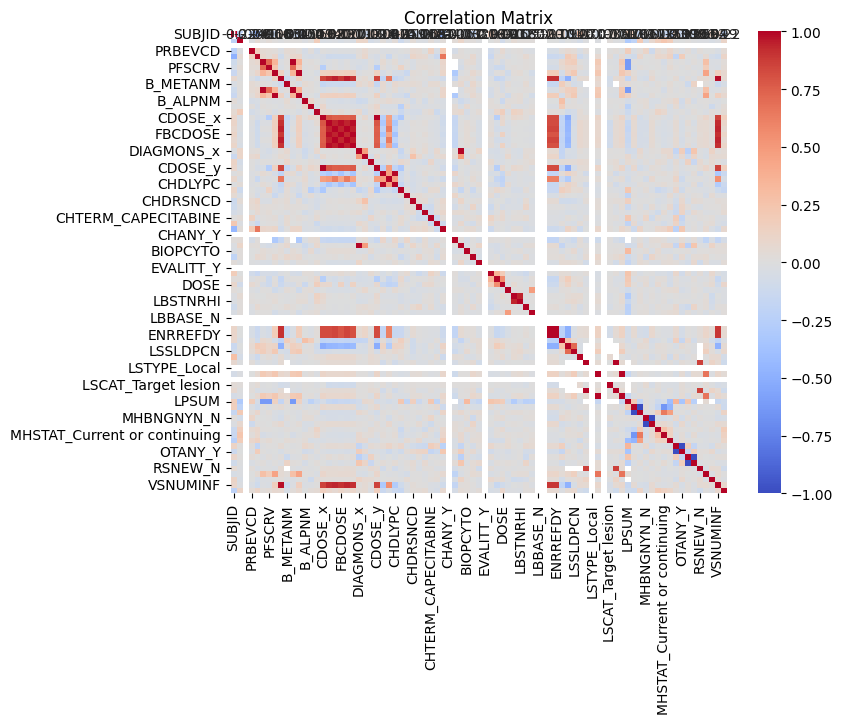

In [12]:
numeric_df = df.select_dtypes(include=['number'])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [13]:
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')
correlation_matrix = df.corr()

In [14]:
correlation_matrix

,SUBJID,AGE,SEXCD,TRTDOSE,ATRT,PRBEVCD,PROXACDR,PROXAM,PFSCR,PFSCRV,...,MHSTAT_Resolved,OTANY_N,OTANY_Y,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_Y,VSNUMINF,VSSTRES
SUBJID,1.000000,-0.217524,NaN,NaN,NaN,-0.238642,-0.490170,NaN,-0.101958,-0.065959,...,-0.234770,0.128044,-0.128044,0.095571,-0.095571,0.059394,-0.053508,0.122326,0.098762,-0.218591
AGE,-0.217524,1.000000,NaN,NaN,NaN,-0.010713,0.051688,NaN,0.013772,0.034093,...,0.183640,0.006797,-0.006797,0.010160,-0.010160,-0.020160,-0.018698,-0.042659,-0.015856,0.110055
SEXCD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRTDOSE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ATRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RSNEW_N,0.059394,-0.020160,NaN,NaN,NaN,0.024388,-0.041379,NaN,-0.014282,-0.010207,...,-0.004764,-0.022792,0.022792,0.021149,-0.021149,1.000000,-0.041764,0.067161,0.050135,-0.097680
RSNEW_Y,-0.053508,-0.018698,NaN,NaN,NaN,-0.001430,0.049984,NaN,0.276946,0.181337,...,-0.019912,-0.027413,0.027413,-0.003852,0.003852,-0.041764,1.000000,-0.020223,0.060824,0.001927
SXANY_Y,0.122326,-0.042659,NaN,NaN,NaN,-0.006188,-0.075418,NaN,-0.024006,-0.018526,...,0.007465,-0.081153,0.081153,-0.012894,0.012894,0.067161,-0.020223,1.000000,0.028321,-0.022723
VSNUMINF,0.098762,-0.015856,NaN,NaN,NaN,-0.034384,-0.105175,NaN,-0.022134,-0.035135,...,-0.012132,0.051578,-0.051578,0.027079,-0.027079,0.050135,0.060824,0.028321,1.000000,0.082385


# PCA


In [29]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

In [37]:
df1=df
df1=df1.drop(columns=['SUBJID','SEXCD', 'ATRT', 'PROXAM', 'KRAS', 'TUMCAT', 'LIVRONLY', 'BIOPRS',
       'BIOPACPT'])

In [38]:
numeric_columns = df1.select_dtypes(include=['number']).columns
numerical_df = df1[numeric_columns]

In [39]:
numerical_df.head()

,AGE,TRTDOSE,PRBEVCD,PROXACDR,PFSCR,PFSCRV,PDLR,TRTDUR,B_METANM,PFSCR.1,...,MHSTAT_Resolved,OTANY_N,OTANY_Y,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_Y,VSNUMINF,VSSTRES
0,54.0,6.0,1.0,1.0,1.0,1.0,1.0,219.0,4.0,1.0,...,0,0,1,1,0,1,1,1,7.520000,58.039000
1,66.0,6.0,1.0,1.0,1.0,1.0,1.0,60.0,3.0,1.0,...,0,1,0,1,0,1,1,1,2.150000,54.807500
2,58.0,6.0,0.0,1.0,1.0,1.0,1.0,437.0,3.0,1.0,...,0,1,0,1,0,1,0,1,13.037267,55.933540
3,75.0,6.0,1.0,1.0,1.0,1.0,1.0,220.0,2.0,1.0,...,1,1,0,1,0,1,1,1,7.063158,59.712632
4,52.0,NaN,1.0,1.0,0.0,0.0,0.0,3.0,3.0,0.0,...,1,1,0,1,0,1,0,1,0.000000,54.091667


In [40]:
numerical_df.shape

(946, 82)

In [41]:
imputer = SimpleImputer(strategy='mean')
numerical_df_imputed_array = imputer.fit_transform(numerical_df)

In [42]:
print(numerical_df.shape)  # Original shape of the DataFrame
print(numerical_df_imputed_array.shape)  # Shape after imputation
print(len(numeric_columns))  # Number of columns in numeric_columns


(946, 82)
(946, 82)
82


In [43]:
numerical_df_imputed = pd.DataFrame(numerical_df_imputed_array, columns=numeric_columns)

In [45]:
print("Imputed numerical_df shape:", numerical_df_imputed.shape)

Imputed numerical_df shape: (946, 82)


In [48]:
pca = PCA(n_components=82)
pca_result = pca.fit_transform(numerical_df_imputed)

In [49]:
pca

PCA(n_components=82)

In [50]:
pca_df = pd.DataFrame(data=pca_result, columns=[f'PC{i+1}' for i in range(82)]) 

In [51]:
explained_variance = pca.explained_variance_ratio_
print(f'Explained variance by each component: {explained_variance}')

Explained variance by each component: [9.40006036e-01 4.82799612e-02 8.03055741e-03 2.20467363e-03
 7.27422211e-04 3.75995565e-04 1.66144592e-04 6.49409393e-05
 5.83205155e-05 4.16758339e-05 3.02857746e-05 4.87304701e-06
 3.32759651e-06 1.46497669e-06 8.70001567e-07 5.61820032e-07
 5.00274142e-07 4.13854854e-07 3.21652070e-07 3.07845759e-07
 2.52261370e-07 2.34940361e-07 1.96745437e-07 1.91536367e-07
 1.60897139e-07 7.66203992e-08 5.94215546e-08 4.62186407e-08
 2.90610176e-08 2.58070055e-08 2.31661150e-08 2.11226446e-08
 1.51171884e-08 4.00225511e-09 1.75943472e-09 1.43246671e-09
 1.22791161e-09 9.17712287e-10 4.43873826e-10 3.56643540e-10
 2.71752054e-10 2.42786476e-10 2.23125081e-10 2.17400024e-10
 1.92286863e-10 1.75564177e-10 1.27471715e-10 1.00998500e-10
 9.64147095e-11 8.30522093e-11 7.58077164e-11 7.10042011e-11
 6.76992117e-11 5.93965678e-11 5.78612009e-11 5.12157401e-11
 4.79781250e-11 3.61162795e-11 3.38276652e-11 1.30652066e-11
 8.38641016e-12 7.42463574e-12 7.07107619e-13 4

In [52]:
df_pca = pd.concat([df, pca_df], axis=1)

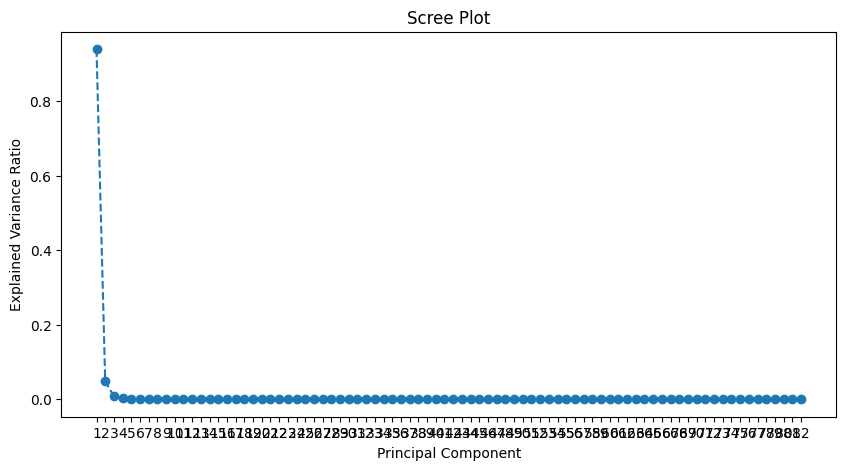

In [53]:
# Plot the scree plot
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, len(explained_variance) + 1))  # Adjust x-ticks to show all components
plt.show()

# Correlation Test

# Numerical Vs Numerical Comparisons (Pearson,Spearman,Kendall Tests)

In [70]:
from scipy.stats import spearmanr, pearsonr, kendalltau
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns
categorical_columns=df.select_dtypes(include=['object']).columns

In [71]:
print(categorical_columns)
print(numeric_columns)

Index(['SEXCD', 'ATRT', 'PROXAM', 'KRAS', 'TUMCAT', 'LIVRONLY', 'BIOPRS',
       'BIOPACPT'],
      dtype='object')
Index(['Unnamed: 0', 'SUBJID', 'AGE', 'TRTDOSE', 'PRBEVCD', 'PROXACDR',
       'PFSCR', 'PFSCRV', 'PDLR', 'TRTDUR', 'B_METANM', 'PFSCR.1', 'PDLR.1',
       'B_ALPNM', 'B_CEA', 'B_CREAT', 'CDOSE_x', 'IRCDOSE', 'FBDUR', 'FBCDOSE',
       'FIDUR', 'FICDOSE', 'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'CDOSE_y',
       'DSDLYPC', 'CHDLYNM', 'CHDLYPC', 'PROPDOSE', 'CHRESPCD', 'CHDRSNCD',
       'CHTERM_5 FU', 'CHTERM_5-FU', 'CHTERM_CAPECITABINE',
       'CHTERM_LEUCOVORIN', 'CHTERM_OXALIPLATIN', 'CHANY_Y', 'DTCAUSCD',
       'DIAGMONS_y', 'BIOPCYTO', 'PFUP', 'KRASCD', 'EVALITT_Y', 'EXDURMN',
       'ACTTRTCD', 'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN',
       'LBBLRES', 'LBBASE_N', 'LBBASE_Y', 'DOSREFDY', 'ENRREFDY', 'LSSLD',
       'LSSLDPCH', 'LSSLDPCN', 'LSRI', 'LSTYPE_Central', 'LSTYPE_Local',
       'LSCAT_New lesion', 'LSCAT_Non-target lesion', 'LSCAT_Target lesio

In [72]:
spearman_corr = df[numeric_columns].corr(method='spearman')
pearson_corr = df[numeric_columns].corr(method='pearson')
kendall_corr = df[numeric_columns].corr(method='kendall')

In [73]:
for col1 in numeric_columns:
    for col2 in numeric_columns:
        if col1 != col2:
            spearman_corr_val, spearman_p_val = spearmanr(df[col1], df[col2])
            print(f"Spearman correlation between {col1} and {col2}: {spearman_corr_val} (p-value: {spearman_p_val})")

Spearman correlation between Unnamed: 0 and SUBJID: 0.9999999999999998 (p-value: 0.0)
Spearman correlation between Unnamed: 0 and AGE: -0.20895063705717096 (p-value: 8.584196003272301e-11)
Spearman correlation between Unnamed: 0 and TRTDOSE: nan (p-value: nan)
Spearman correlation between Unnamed: 0 and PRBEVCD: -0.21155143414394695 (p-value: 4.943199425048063e-11)
Spearman correlation between Unnamed: 0 and PROXACDR: -0.43262543450557733 (p-value: 1.9835593979966542e-44)
Spearman correlation between Unnamed: 0 and PFSCR: -0.0983430439152213 (p-value: 0.0024610334052471714)
Spearman correlation between Unnamed: 0 and PFSCRV: -0.0555337036560271 (p-value: 0.0878005746797722)
Spearman correlation between Unnamed: 0 and PDLR: -0.14405665575759202 (p-value: 8.662141455215598e-06)
Spearman correlation between Unnamed: 0 and TRTDUR: 0.08971278020004303 (p-value: 0.005758457930321151)
Spearman correlation between Unnamed: 0 and B_METANM: nan (p-value: nan)
Spearman correlation between Unnamed

In [75]:
df_clean = df.replace([np.inf, -np.inf], np.nan).dropna()

numeric_columns = df_clean.select_dtypes(include=[np.number]).columns

# Calculate Pearson correlation
for col1 in numeric_columns:
    for col2 in numeric_columns:
        if col1 != col2:
            pearson_corr_val, pearson_p_val = pearsonr(df_clean[col1], df_clean[col2])
            print(f"Pearson correlation between {col1} and {col2}: {pearson_corr_val} (p-value: {pearson_p_val})")

Pearson correlation between Unnamed: 0 and SUBJID: 0.9827333320679638 (p-value: 1.1742321150708043e-08)
Pearson correlation between Unnamed: 0 and AGE: -0.27284855647428496 (p-value: 0.3908777065897828)
Pearson correlation between Unnamed: 0 and TRTDOSE: nan (p-value: nan)
Pearson correlation between Unnamed: 0 and PRBEVCD: -0.4835109811704499 (p-value: 0.11126447251884657)
Pearson correlation between Unnamed: 0 and PROXACDR: -0.3661224059932545 (p-value: 0.24181029578109653)
Pearson correlation between Unnamed: 0 and PFSCR: nan (p-value: nan)
Pearson correlation between Unnamed: 0 and PFSCRV: nan (p-value: nan)
Pearson correlation between Unnamed: 0 and PDLR: nan (p-value: nan)
Pearson correlation between Unnamed: 0 and TRTDUR: 0.09303012088029118 (p-value: 0.7736800554073557)
Pearson correlation between Unnamed: 0 and B_METANM: 0.06144335403776871 (p-value: 0.8495503035594814)
Pearson correlation between Unnamed: 0 and PFSCR.1: nan (p-value: nan)
Pearson correlation between Unnamed: 

In [76]:
for col1 in numeric_columns:
    for col2 in numeric_columns:
        if col1 != col2:
            kendall_corr_val, kendall_p_val = kendalltau(df[col1], df[col2])
            print(f"Kendall correlation between {col1} and {col2}: {kendall_corr_val} (p-value: {kendall_p_val})")

Kendall correlation between Unnamed: 0 and SUBJID: 1.0 (p-value: 0.0)
Kendall correlation between Unnamed: 0 and AGE: -0.1434328259692539 (p-value: 7.12273471442079e-11)
Kendall correlation between Unnamed: 0 and TRTDOSE: nan (p-value: nan)
Kendall correlation between Unnamed: 0 and PRBEVCD: -0.17282229402145122 (p-value: 7.859182165368759e-11)
Kendall correlation between Unnamed: 0 and PROXACDR: -0.35342383919934434 (p-value: 2.337248985688103e-40)
Kendall correlation between Unnamed: 0 and PFSCR: -0.08033918805256733 (p-value: 0.002501590503688508)
Kendall correlation between Unnamed: 0 and PFSCRV: -0.0453670385179786 (p-value: 0.08779354731155313)
Kendall correlation between Unnamed: 0 and PDLR: -0.11768391841837061 (p-value: 9.492398924964812e-06)
Kendall correlation between Unnamed: 0 and TRTDUR: 0.06159457883181966 (p-value: 0.004757871904289841)
Kendall correlation between Unnamed: 0 and B_METANM: nan (p-value: nan)
Kendall correlation between Unnamed: 0 and PFSCR.1: -0.08033918

# Categorical Vs Categorical Tests (Chi-Square Test)

In [77]:
from scipy.stats import chi2_contingency
from scipy import stats
print("\nStatistical tests for categorical vs. categorical columns:")
for col1 in categorical_columns:
    for col2 in categorical_columns:
        if col1 != col2:
            contingency_table = pd.crosstab(df[col1], df[col2])
            chi2_stat, chi2_p, _, _ = chi2_contingency(contingency_table)
            print(f"{col1} vs. {col2}: Chi-square statistic = {chi2_stat}, p-value = {chi2_p}")



Statistical tests for categorical vs. categorical columns:
SEXCD vs. ATRT: Chi-square statistic = 3.5517255414384272, p-value = 0.05948356187558913
SEXCD vs. PROXAM: Chi-square statistic = 2.8640604848536433, p-value = 0.09057858623604977
SEXCD vs. KRAS: Chi-square statistic = 5.6557024177376505, p-value = 0.05913979630379713
SEXCD vs. TUMCAT: Chi-square statistic = 8.96251443234161, p-value = 0.002755753572433804
SEXCD vs. LIVRONLY: Chi-square statistic = 0.001263016928216076, p-value = 0.9716499888072977
SEXCD vs. BIOPRS: Chi-square statistic = 2.1366279615016626, p-value = 0.3435873241842649
SEXCD vs. BIOPACPT: Chi-square statistic = 0.7776873509453173, p-value = 0.37784936453929086
ATRT vs. SEXCD: Chi-square statistic = 3.5517255414384272, p-value = 0.05948356187558913
ATRT vs. PROXAM: Chi-square statistic = 0.019730737143052554, p-value = 0.8882917017354437
ATRT vs. KRAS: Chi-square statistic = 0.6647376452644074, p-value = 0.7172227460854047
ATRT vs. TUMCAT: Chi-square statistic

# Numerical Vs Categorical Tests (t-test,ANOVA way)

In [78]:
from scipy.stats import f_oneway
import itertools

print("\nStatistical tests for numerical vs. categorical columns:")
unique_comparisons = set()
for col1, col2 in itertools.product(numeric_columns, categorical_columns):
    comparison_key = (col1, col2)
    if comparison_key not in unique_comparisons:
        unique_comparisons.add(comparison_key)
        f_stat, f_p_value = f_oneway(*[df[df[col2] == cat][col1] for cat in df[col2].unique()])
        print(f"{col1} across different categories of {col2}: F-statistic = {f_stat}, p-value = {f_p_value}")


Statistical tests for numerical vs. categorical columns:
Unnamed: 0 across different categories of SEXCD: F-statistic = 10.12129401332613, p-value = 0.0015135112115984139
Unnamed: 0 across different categories of ATRT: F-statistic = 0.014315588239095005, p-value = 0.904787636283245
Unnamed: 0 across different categories of PROXAM: F-statistic = 225.38964207353118, p-value = 7.585224279570757e-46
Unnamed: 0 across different categories of KRAS: F-statistic = nan, p-value = nan
Unnamed: 0 across different categories of TUMCAT: F-statistic = 2.3620877570390437, p-value = 0.12465080693158777
Unnamed: 0 across different categories of LIVRONLY: F-statistic = 2.7391063098600257, p-value = 0.09825190820980288
Unnamed: 0 across different categories of BIOPRS: F-statistic = nan, p-value = nan
Unnamed: 0 across different categories of BIOPACPT: F-statistic = nan, p-value = nan
SUBJID across different categories of SEXCD: F-statistic = 12.756278851179799, p-value = 0.0003727324145684633
SUBJID acr